# 07 · M2: Gemma 4 12B, zero-shot vs LoRA

End-to-end experiment for one backbone: data → zero-shot inference → LoRA fine-tuning → LoRA inference → evaluation on dev
(200 videos) and the held-out test set (1,448 videos, run once with the frozen configuration in `configs/frozen_test.json`).

In [1]:
%matplotlib inline
import json, statistics
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import pandas as pd
from nbcommon import *

pd.set_option("display.max_colwidth", 80)
RUN_GPU = False   # True only on the training/inference machine (needs the models and a GPU)
print("project:", ROOT.name, "| run outputs read from:", A.relative_to(ROOT))

project: FinalProject | run outputs read from: artifacts


## 0. Configuration

In [2]:
ALIAS = "M2"
spec = BACKBONES[ALIAS]
frozen = load_json(ROOT / "configs/frozen_test.json")
display(pd.Series({"model": spec["model_id"], "revision": spec["revision"], "family": spec["family"],
                   "inference engine": "HF batched greedy" if spec["engine"] == "seq2seq" else "vLLM, native thinking",
                   "LoRA adapter": rel(spec["train_dir"] / "adapter")}))
print("frozen entries for this backbone:", [c for c in frozen["configurations"] if ALIAS in c] if isinstance(frozen.get("configurations"), dict) else "see configs/frozen_test.json")

model                                    google/gemma-4-12B-it
revision              43c9d014b231474fa7212dbb48a762566c2b255d
family                                            decoder-only
inference engine                         vLLM, native thinking
LoRA adapter        artifacts/stage5-v1/M2-direct-safe/adapter
dtype: str

frozen entries for this backbone: ['M2-ZS', 'M2-FT']


## 1. Data

All runs use the same window packs (notebook 02):
* **Training:** 1,000 training videos (1,306 windows), used for LoRA only.
* **Dev:** 200 validation videos (270 windows), used to select settings before the freeze.
* **Test:** 1,448 test videos (1,905 windows), run once.

In [3]:
dev_records, test_records = load_jsonl(DEV_RECORDS), load_jsonl(TEST_RECORDS)
print("dev:", len(dev_records), "videos,", sum(1 for _ in open(DEV_WINDOWS)), "windows")
print("test:", len(test_records), "videos,", sum(1 for _ in open(TEST_WINDOWS)), "windows")
print("train:", sum(1 for _ in open(TRAIN_WINDOWS)), "windows")

dev: 200 videos, 270 windows
test: 1448 videos, 1905 windows
train: 1306 windows


## 2. Zero-shot inference

The base model receives the window prompt, and its answer is parsed strictly. Inference settings are identical for zero-shot and LoRA.

Decoder-only models run in **vLLM** with native thinking enabled and not forced:
* Model-card sampling: temperature 1.0, top-p 0.95, top-k 20 for Qwen (presence penalty 1.5) or 64 for Gemma.
* A per-window seed.
* Up to 32,768 new tokens.

The final JSON is taken after the model's native end-of-thinking marker.

In [4]:
for split in ["dev", "test"]:
    run(infer_command(ALIAS, split, "ZS"), RUN_GPU)

[not run here; RUN_GPU=False]  $ $VLLM_PYTHON scripts/infer_vllm_pair.py --alias M2 --arms ZS FT --adapter artifacts/stage5-v1/M2-direct-safe/adapter --windows artifacts/windows/dev-v2/validation_windows.jsonl --output artifacts/stage5-v1/M2-dev --max-num-seqs 100 --batch-size 100 --max-new-tokens 32768
[not run here; RUN_GPU=False]  $ $VLLM_PYTHON scripts/infer_vllm_pair.py --alias M2 --arms ZS FT --adapter artifacts/stage5-v1/M2-direct-safe/adapter --windows artifacts/windows/test-v1/test_windows.jsonl --output artifacts/heldout-test-v1/M2 --max-num-seqs 100 --batch-size 100 --max-new-tokens 32768


In [5]:
def summary(split, arm):
    d = spec["runs"][(split, arm)]
    return load_json(d / "summary.json")

rows = []
for split in ["dev", "test"]:
    for arm in ["ZS", "FT"]:
        s = summary(split, arm)
        rows.append({"split": split, "arm": arm, "videos": s["requested_videos"], "windows": s["requested_windows"],
                     **{f"videos {k}": v for k, v in sorted(s["status_counts"].items())},
                     "generation min": round(s["generation_seconds"] / 60, 1), "output tokens": s["completion_tokens"]})
display(pd.DataFrame(rows).fillna(0).set_index(["split", "arm"]))

videos  windows  videos ok  generation min  output tokens  \
split arm                                                              
dev   ZS      200      270        200             7.2        1504030   
      FT      200      270        192             1.8          34239   
test  ZS     1448     1905       1447            56.7       10287209   
      FT     1448     1905       1402             6.3         170337   

           videos invalid  
split arm                  
dev   ZS              0.0  
      FT              8.0  
test  ZS              1.0  
      FT             46.0

In [6]:
# One raw zero-shot answer for a test window. Decoder-only output is a thought, then the final JSON.
raw = load_jsonl(spec["runs"][("test", "ZS")] / "windows.jsonl")
print("window statuses:", dict(Counter(r["status"] for r in raw)))
for wanted in ["ok", "failed"]:
    example = next((r for r in raw if (r["status"] == "ok") == (wanted == "ok")), None)
    if example is None:
        continue
    text = example.get("raw_text") or ""
    print(f"\n=== first {wanted} window: {example['video_id']} #{example['window_index']} | status {example['status']} | error {example.get('error')}")
    print("raw output:", len(text), "characters | reasoning tokens:", (example.get("usage") or {}).get("reasoning_tokens"))
    print(text[:600] + (" ..." if len(text) > 600 else ""))
    if example.get("final_text") and example["final_text"] != text:
        print("final answer:", example["final_text"][:400])

window statuses: {'ok': 1904, 'invalid': 1}

=== first ok window: synIg0Orgr0 #0 | status ok | error None
raw output: 16143 characters | reasoning tokens: 4984
<|channel>thought
Divide the visible transcript [0, 254) into contiguous topical chapters.
Concise, specific title supported only by visible text. Do not rewrite transcript.
Bracketed numbers are sentence indices. Start 0 must be included.

        *   Only include starts in the visible context [0, 254).
        *   Ownership edges don't create boundaries.
        *   Choose count from visible content.
        *   Strictly increasing integer starts from 0-253.
        *   Nonempty titles.
        *   Return only one JSON object.

    *   [0-5] Introduction (Chad's Prep, link, playlist, etc.).
 ...
final answer: {"chapters":[{"start":0,"title":"Galvanic Cells"},{"start":6,"title":"Electrochemical cells"},{"start":15,"title":"Spontaneous reaction"},{"start":31,"title":"Galvanic cells, your batteries"},{"start":44,"title":"Anode an

## 3. LoRA fine-tuning

* **Adapter:** LoRA rank 16, alpha 32, dropout 0.05, on q/k/v/o projections; the base model stays frozen (bf16).
* **Optimizer:** AdamW at 2e-4 with cosine decay and 10 warmup steps; gradient clipping 1.0.
* **Batching:** one window per forward pass, gradient accumulation 8, one pass over the 1,306 training windows.

The loss covers **only the final JSON answer** plus the native turn-end token, rendered with the model's chat template. The prompt is unscored, and no reasoning text is invented or supervised.

In [7]:
run(train_command(ALIAS), RUN_GPU)
report = load_json(spec["train_dir"] / "report.json")
keep = ["final_context", "rank", "lora_alpha", "lora_dropout", "target_modules", "learning_rate", "lr_schedule", "warmup_steps",
        "grad_accum", "actual_steps", "planned_optimizer_steps", "actual_training_videos", "trainable_parameters",
        "teacher_forcing_tokens", "first_loss", "last_loss", "mean_loss", "training_seconds", "peak_allocated_bytes",
        "optimizer_update_verified", "save_reload_adapter_tensors_equal"]
display(pd.Series({k: report.get(k) for k in keep}))

[not run here; RUN_GPU=False]  $ python scripts/train_lora.py --alias M2 --windows artifacts/windows/dev-v2/train_windows.jsonl --max-steps 0 --target-modules q_proj,k_proj,v_proj,o_proj --learning-rate 2e-4 --lr-schedule cosine --checkpoint-every 100 --grad-accum 8 --warmup-steps 10 --output artifacts/stage5-v1/M2-direct-safe


final_context                                               direct_v1
rank                                                               16
lora_alpha                                                         32
lora_dropout                                                     0.05
target_modules                       [q_proj, k_proj, v_proj, o_proj]
learning_rate                                                  0.0002
lr_schedule                                                    cosine
warmup_steps                                                       10
grad_accum                                                          8
actual_steps                                                     1306
planned_optimizer_steps                                           164
actual_training_videos                                           1000
trainable_parameters                                         21331968
teacher_forcing_tokens                                        5924802
first_loss          

{'adapter_model.safetensors': '81.4 MiB', 'README.md': '0.0 MiB', 'adapter_config.json': '0.0 MiB'}


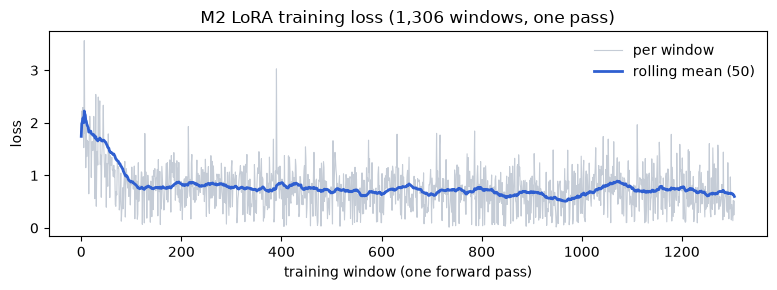

In [8]:
plot_loss(spec["train_dir"] / "steps.jsonl", "M2 LoRA training loss (1,306 windows, one pass)")
plt.tight_layout()
adapter = spec["train_dir"] / "adapter"
print({p.name: f"{p.stat().st_size / 2**20:.1f} MiB" for p in adapter.iterdir()} if adapter.exists() else "adapter not downloaded")

## 4. LoRA inference (same engine and settings, adapter loaded)

In [9]:
for split in ["dev", "test"]:
    if spec["engine"] == "seq2seq":
        run(infer_command(ALIAS, split, "FT"), RUN_GPU)
    else:
        print(f"{split}: the LoRA arm ran in the same vLLM call as zero-shot (--arms ZS FT), shown above")

dev: the LoRA arm ran in the same vLLM call as zero-shot (--arms ZS FT), shown above
test: the LoRA arm ran in the same vLLM call as zero-shot (--arms ZS FT), shown above


## 5. Evaluation

The saved predictions are re-scored with the project evaluator and checked against the saved evaluation files. The full metric set and the paired bootstrap come from `scripts/evaluate_predictions.py`.

In [10]:
recomputed, results = {}, []
for split, records in [("dev", DEV_RECORDS), ("test", TEST_RECORDS)]:
    for arm in ["ZS", "FT"]:
        recomputed[(split, arm)] = recompute(records, spec["runs"][(split, arm)] / "predictions.jsonl")
    saved_ft, saved_zs, saved_boot = paired_metrics(paired_file(ALIAS, split))
    assert abs(recomputed[(split, "FT")]["aggregate"]["macro_exact_f1"] - saved_ft["exact_f1"]) < 1e-12
    assert abs(recomputed[(split, "ZS")]["aggregate"]["macro_exact_f1"] - saved_zs["exact_f1"]) < 1e-12
    results += [(f"{split} zero-shot", saved_zs), (f"{split} LoRA", saved_ft)]
    print(f"{split}: LoRA − zero-shot exact F1 = {saved_boot['mean_difference']:+.3f} "
          f"[{saved_boot['confidence_interval'][0]:+.3f}, {saved_boot['confidence_interval'][1]:+.3f}] "
          f"(paired bootstrap, {saved_boot['videos']} videos)")
print("re-scored exact F1 matches the saved evaluation for all four runs")
display(metric_table(results))

dev: LoRA − zero-shot exact F1 = -0.114 [-0.144, -0.084] (paired bootstrap, 200 videos)


test: LoRA − zero-shot exact F1 = -0.108 [-0.119, -0.096] (paired bootstrap, 1448 videos)
re-scored exact F1 matches the saved evaluation for all four runs


,videos,failed,exact_f1,tolerant_f1,pk,window_diff,boundary_similarity,title_rouge_l,title_bertscore,pred_per_ref
configuration,,,,,,,,,,
dev zero-shot,200,0,0.459,0.649,0.283,0.342,0.430,0.305,0.692,1.464
dev LoRA,200,8,0.346,0.543,0.310,0.333,0.339,0.272,0.484,0.786
test zero-shot,1448,1,0.451,0.643,0.286,0.347,0.420,0.303,0.677,1.477
test LoRA,1448,46,0.344,0.540,0.306,0.326,0.334,0.282,0.507,0.812


In [11]:
lenient = {arm: metrics(load_json(TEST / f"envelope-{ALIAS}-{arm}-metrics.json")) for arm in ["ZS", "FT"]}
print("Secondary lenient reading on test (one Markdown fence / trailing period stripped):")
display(metric_table([("test zero-shot (lenient)", lenient["ZS"]), ("test LoRA (lenient)", lenient["FT"])]))

Secondary lenient reading on test (one Markdown fence / trailing period stripped):


,videos,failed,exact_f1,tolerant_f1,pk,window_diff,boundary_similarity,title_rouge_l,title_bertscore,pred_per_ref
configuration,,,,,,,,,,
test zero-shot (lenient),1448,1,0.451,0.643,0.286,0.347,0.420,0.303,0.677,1.477
test LoRA (lenient),1448,46,0.344,0.540,0.306,0.326,0.334,0.282,0.507,0.812


## 6. One test video: gold vs zero-shot vs LoRA

In [12]:
zs_pred, ft_pred = by_id(spec["runs"][("test", "ZS")] / "predictions.jsonl"), by_id(spec["runs"][("test", "FT")] / "predictions.jsonl")
window_count = Counter(json.loads(line)["window"]["video_id"] for line in open(TEST_WINDOWS))
# first single-window test video of moderate length (display only; nothing is selected or tuned on test)
example = next(r for r in test_records if window_count[r["video_id"]] == 1 and 60 <= len(r["sentences"]) <= 120
               and 5 <= len(r["reference"]["chapter_starts"]) <= 9)
vid = example["video_id"]
print(vid, "|", len(example["sentences"]), "sentences | ZS status:", zs_pred[vid]["status"], "| LoRA status:", ft_pred[vid]["status"])
display(chapters_side_by_side(example, {"zero-shot": zs_pred[vid], "LoRA": ft_pred[vid]}))

_-x90wGBD8U | 119 sentences | ZS status: ok | LoRA status: ok


,gold,zero-shot,LoRA
start sentence,,,
0,Introduction,Log to the base 10 and log to the base e,Base of Natural Log
7,Natural Log,,
12,,What is this e?,
14,Understanding Growth,Understand GROWTH,
32,,Gradual and Discontinuous growth,
49,Growth Formula,100 percent growth rate,
82,,Formula for n time periods,
98,What is e?,Layman friendly explanation for e,
107,Value of e,,


## 7. Error analysis

In [13]:
# Exact F1 on test by number of windows per video.
rows = []
for arm in ["ZS", "FT"]:
    buckets = defaultdict(list)
    for score in recomputed[("test", arm)]["per_video"]:
        buckets[min(window_count[score["video_id"]], 3)].append(score["exact"]["f1"])
    rows.append({"arm": arm, **{("3+ windows" if k == 3 else f"{k} window" + ("s" if k > 1 else "")): round(statistics.mean(v), 3)
                               for k, v in sorted(buckets.items())},
                 **{f"status {k}": v for k, v in recomputed[("test", arm)]["aggregate"]["status_counts"].items()}})
display(pd.DataFrame(rows).fillna(0).set_index("arm"))

,1 window,2 windows,3+ windows,status ok,status invalid
arm,,,,,
ZS,0.498,0.228,0.172,1447,1
FT,0.387,0.141,0.085,1402,46


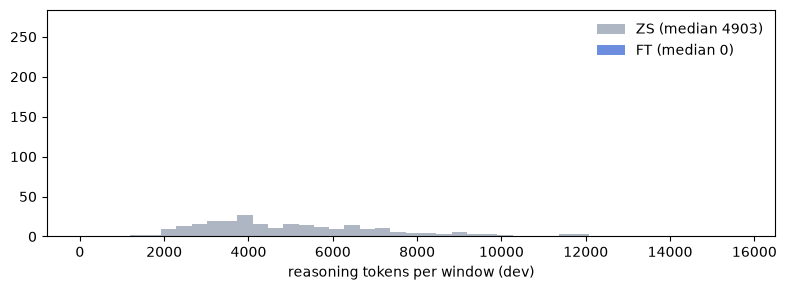

In [14]:
# Native thinking: reasoning tokens per dev window, zero-shot vs LoRA.
fig, ax = plt.subplots(figsize=(8, 3))
for arm, color in [("ZS", "#8a97a8"), ("FT", "#2f5fd0")]:
    tokens = [(r.get("usage") or {}).get("reasoning_tokens") or 0 for r in load_jsonl(spec["runs"][("dev", arm)] / "windows.jsonl")]
    ax.hist(tokens, bins=40, alpha=.7, color=color, label=f"{arm} (median {int(statistics.median(tokens))})")
ax.set_xlabel("reasoning tokens per window (dev)"); ax.legend(frameon=False); plt.tight_layout()

## 8. Takeaway

Zero-shot M2 is the best decoder-only system (0.451 test). Answer-only LoRA makes it stop thinking entirely (median 4,907 → 0 tokens) and under-segment (predicted/reference chapters 1.48 → 0.81): 0.344 on test (−0.108). RFT restores thinking but stays at zero-shot level.